# What Makes a Hindi Film Score Well on IMDb?

**Question:** Which genres, runtimes, release months and directors go with higher IMDb ratings?

**Data**
- `READY_hindi_films_with_month_runtime_genre.csv`: the **base table** (all 15,179 Hindi films, 1980–2023).
- `TMDB_movie_dataset_v11.csv`: joined with a **LEFT join** only to add `vote_count` and a backup `runtime`. A left join means no film is lost just because TMDB does not know it.

**Steps**
1. Keep rated feature films and document every drop
2. Average rating by genre, release month and runtime band
3. Sequel vs original (with a hand check)
4. Director track record (earlier films only, no future information)
5. Three recommendations backed by numbers, plus limits

**How to run:** change the three paths in the setup cell, then *Run All*. Every number in the final summary is computed from the data, so nothing in it can go out of date.

# Setup

In [1]:
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

# ---- paths (change these) ----
READY_CSV = r"C:\Users\HP\Downloads\DA-09_Hindi_films\READY_hindi_films_with_month_runtime_genre.csv"
TMDB_CSV  = r"C:\Users\HP\Downloads\TMDB_movie_dataset_v11.csv"
DB_PATH   = "hindi_films.db"          # created next to this notebook

# ---- analysis settings ----
MIN_VOTES           = 100    # minimum TMDB votes for the robustness check (Section 8)
MIN_FILMS_PER_GROUP = 15     # groups smaller than this are not ranked (too noisy)
DROP_SHORTS         = True   # task says: feature films only
DROP_DOCUMENTARIES  = True   # a production house is choosing which fiction to make; set False to keep them

# Loading the data and building the working table

The READY file is the base. TMDB is joined on `imdb_id` **only** to add `vote_count` and a backup runtime. (Earlier versions used an inner join with a TMDB "Hindi + India" table, which silently dropped about two thirds of the films.)

In [2]:
ready = pd.read_csv(READY_CSV)

required = ["name", "imdb_id", "rating", "genre", "primary_genre", "release_year",
            "release_month", "runtime_minutes", "main_director", "sequel_guess"]
missing = [c for c in required if c not in ready.columns]
assert not missing, f"READY file is missing columns: {missing}"

print("READY file:", ready.shape)
ready.head(3)

READY file: (15179, 20)


,imdb_id,type,name,url,description,rating,genre,datePublished,keywords,duration,actors,director,creator,runtime_minutes,release_year,release_month,primary_genre,number_of_genres,main_director,sequel_guess
0,tt0246879,Movie,Qurbani,https://www.imdb.com/title/tt0246879/,Two friends live happily until misunderstandin...,7.1,Action | Crime | Drama,1980-06-20,"widower,thief,friendship,father daughter relat...",PT2H37M,Feroz Khan | Vinod Khanna | Zeenat Aman,Feroz Khan,Kader Khan | K.K. Shukla,157.0,1980.0,Jun,Action,3.0,Feroz Khan,NaN
1,tt0081491,Movie,Shaan,https://www.imdb.com/title/tt0081491/,Two brothers go after the international mafia ...,7.1,Action | Adventure | Crime,1980-12-12,"no brakes,murder of a police officer,underwate...",PT3H1M,Sunil Dutt | Shashi Kapoor | Amitabh Bachchan,Ramesh Sippy,Javed Akhtar | Salim Khan,181.0,1980.0,Dec,Action,3.0,Ramesh Sippy,NaN
2,tt0080653,Movie,Dostana,https://www.imdb.com/title/tt0080653/,Vijay Varma (Amitabh Bachchan) and Ravi Kapoor...,6.4,Action | Crime | Drama,1980-10-17,"best friend,friendship between men,tough guy,f...",PT2H32M,Amitabh Bachchan | Shatrughan Sinha | Zeenat Aman,Raj Khosla,Javed Akhtar | Salim Khan,152.0,1980.0,Oct,Action,3.0,Raj Khosla,NaN


In [3]:
# TMDB is large (1.5M rows), so read only the 3 columns we need
tmdb = pd.read_csv(TMDB_CSV, usecols=["imdb_id", "vote_count", "runtime"])
tmdb = (tmdb.dropna(subset=["imdb_id"])
            .sort_values("vote_count", ascending=False)
            .drop_duplicates("imdb_id")                      # one row per imdb_id
            .rename(columns={"runtime": "tmdb_runtime"}))

base = ready.merge(tmdb, on="imdb_id", how="left")          # LEFT join: keeps every READY film
assert len(base) == len(ready), "merge changed the number of rows"

base["rating"] = pd.to_numeric(base["rating"], errors="coerce")   # '\N' or blanks -> NaN
base["title"]  = base["name"]

print(f"Films in READY file         : {len(base):,}")
print(f"Films matched to TMDB votes : {base['vote_count'].notna().sum():,}")

Films in READY file         : 15,179
Films matched to TMDB votes : 5,966


In [4]:
log = []

def drop_step(df, keep_mask, label, why):
    kept = df[keep_mask].copy()
    log.append({"step": label, "films_before": len(df), "dropped": len(df) - len(kept),
                "films_after": len(kept), "why": why})
    return kept

df = base.copy()

# 1) duplicates
dup = df["imdb_id"].notna() & df.duplicated("imdb_id")
df = drop_step(df, ~dup, "Duplicate imdb_id", "same film listed twice")

# 2) unrated films
df = drop_step(df, df["rating"].notna(), "No IMDb rating",
               "no target value, so it cannot contribute to any average")

# 3) not a feature film (TV etc.), if the file has a 'type' column
if "type" in df.columns:
    not_feature = df["type"].notna() & (df["type"] != "Movie")
    df = drop_step(df, ~not_feature, "Not a feature film (type != Movie)",
                   "task asks for feature films only (no TV)")

# 4) short films
if DROP_SHORTS:
    is_short = (df["primary_genre"] == "Short") | df["genre"].fillna("").str.contains(r"\bShort\b")
    df = drop_step(df, ~is_short, "Short films",
                   "task asks for feature films only; shorts also inflate the <100 min runtime band")

# 5) documentaries
if DROP_DOCUMENTARIES:
    df = drop_step(df, df["primary_genre"] != "Documentary", "Documentaries",
                   "not comparable with the fiction films a production house chooses between")

rated = df.copy()

print(f"Started with {len(base):,} films, kept {len(rated):,} rated feature films "
      f"({len(base) - len(rated):,} dropped).")
pd.DataFrame(log)

Started with 15,179 films, kept 6,156 rated feature films (9,023 dropped).


,step,films_before,dropped,films_after,why
0,Duplicate imdb_id,15179,0,15179,same film listed twice
1,No IMDb rating,15179,6342,8837,"no target value, so it cannot contribute to an..."
2,Not a feature film (type != Movie),8837,2007,6830,task asks for feature films only (no TV)
3,Short films,6830,536,6294,task asks for feature films only; shorts also ...
4,Documentaries,6294,138,6156,not comparable with the fiction films a produc...


In [5]:
# Runtime: use IMDb runtime, and fill gaps from TMDB runtime (0 means "unknown" in TMDB)
rated["runtime_final"] = rated["runtime_minutes"]
can_fill = rated["runtime_final"].isna() & (rated["tmdb_runtime"] > 0)
rated.loc[can_fill, "runtime_final"] = rated.loc[can_fill, "tmdb_runtime"]
rated["runtime_final"] = rated["runtime_final"].where(rated["runtime_final"] > 0)

print(f"Runtime missing before fill : {rated['runtime_minutes'].isna().sum():,}")
print(f"Filled from TMDB            : {can_fill.sum():,}")
print(f"Runtime still missing       : {rated['runtime_final'].isna().sum():,} "
      f"({rated['runtime_final'].isna().mean():.0%} of rated films)")

# Sequel flag (will be corrected by hand in Section 4)
rated["sequel_category"] = np.where(rated["sequel_guess"] == "Likely sequel", "Sequel", "Original")
rated["vote_count"] = rated["vote_count"].fillna(0)

Runtime missing before fill : 1,381
Filled from TMDB            : 378
Runtime still missing       : 1,003 (16% of rated films)


In [6]:
# Load the clean table into SQLite
keep = ["imdb_id", "name", "rating", "genre", "primary_genre", "number_of_genres",
        "release_year", "release_month", "runtime_final", "main_director", "actors",
        "sequel_guess", "sequel_category", "vote_count"]
keep = [c for c in keep if c in rated.columns]

conn = sqlite3.connect(DB_PATH)
rated[keep].to_sql("rated_films", conn, if_exists="replace", index=False)

# robustness sample: only films with at least MIN_VOTES TMDB votes
conn.executescript(f"""
    DROP VIEW IF EXISTS rated_films_votes;
    CREATE VIEW rated_films_votes AS
    SELECT * FROM rated_films WHERE vote_count >= {MIN_VOTES};
""")

def q(sql, params=None):
    """Run SQL and return a DataFrame."""
    return pd.read_sql_query(sql, conn, params=params)

q("""SELECT COUNT(*) AS rated_feature_films,
            ROUND(AVG(rating), 2) AS avg_rating,
            MIN(rating) AS min_rating, MAX(rating) AS max_rating
     FROM rated_films""")

,rated_feature_films,avg_rating,min_rating,max_rating
0,6156,5.83,1.2,10.0


# Average rating by genre, release month and runtime band

The queries are wrapped in small functions so the same code can be reused in the robustness check (Section 8).
Groups with fewer than `MIN_FILMS_PER_GROUP` films are not ranked, because a 1-film "genre" is noise.

In [7]:
MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
MONTH_ORDER_SQL = "CASE release_month " + " ".join(
    f"WHEN '{m}' THEN {i + 1}" for i, m in enumerate(MONTHS)) + " END"

RUNTIME_BAND_SQL = """
    CASE WHEN runtime_final IS NULL THEN '5. Unknown'
         WHEN runtime_final < 100   THEN '1. <100 min'
         WHEN runtime_final <= 130  THEN '2. 100-130 min'
         WHEN runtime_final <= 160  THEN '3. 131-160 min'
         ELSE                            '4. 160+ min' END"""

def genre_summary(tbl="rated_films", min_n=MIN_FILMS_PER_GROUP):
    return q(f"""
        SELECT primary_genre, COUNT(*) AS films, ROUND(AVG(rating), 2) AS avg_rating
        FROM {tbl}
        WHERE primary_genre IS NOT NULL AND TRIM(primary_genre) <> ''
        GROUP BY primary_genre
        HAVING COUNT(*) >= {min_n}
        ORDER BY avg_rating DESC""")

def month_summary(tbl="rated_films"):
    return q(f"""
        SELECT release_month, COUNT(*) AS films, ROUND(AVG(rating), 2) AS avg_rating
        FROM {tbl}
        WHERE release_month IS NOT NULL AND TRIM(release_month) <> ''
        GROUP BY release_month
        ORDER BY {MONTH_ORDER_SQL}""")

def runtime_summary(tbl="rated_films"):
    return q(f"""
        SELECT {RUNTIME_BAND_SQL} AS runtime_band, COUNT(*) AS films,
               ROUND(AVG(rating), 2) AS avg_rating
        FROM {tbl}
        GROUP BY runtime_band
        ORDER BY runtime_band""")

def sequel_summary(tbl="rated_films"):
    return q(f"""
        SELECT sequel_category, COUNT(*) AS films, ROUND(AVG(rating), 2) AS avg_rating
        FROM {tbl}
        GROUP BY sequel_category
        ORDER BY sequel_category""")

def tier_summary(where=""):
    return q(f"""
        SELECT CASE WHEN prior_films = 0   THEN '1. No earlier film in data'
                    WHEN prior_films = 1   THEN '2. One earlier film'
                    WHEN prior_avg >= 7.0  THEN '3. Strong record (avg 7.0+)'
                    WHEN prior_avg >= 5.5  THEN '4. Average record (5.5-6.99)'
                    ELSE                        '5. Weak record (below 5.5)' END AS director_tier,
               COUNT(*) AS films, ROUND(AVG(current_rating), 2) AS avg_rating
        FROM director_scored {where}
        GROUP BY director_tier
        ORDER BY director_tier""")

# By primary genre

In [8]:
genre = genre_summary()
small = q("""SELECT COUNT(*) AS n FROM (SELECT primary_genre FROM rated_films
             GROUP BY primary_genre HAVING COUNT(*) < ?)""", (MIN_FILMS_PER_GROUP,)).iloc[0, 0]
print(f"{small} genre(s) with fewer than {MIN_FILMS_PER_GROUP} films are not ranked.")
genre

6 genre(s) with fewer than 15 films are not ranked.


,primary_genre,films,avg_rating
0,Reality-TV,16,7.23
1,Biography,92,7.05
2,Animation,85,6.82
3,Adventure,80,6.52
4,Fantasy,30,6.35
5,Drama,1728,6.15
6,Crime,308,6.13
7,Family,53,6.07
8,Thriller,149,5.85
9,Comedy,1039,5.80


### 3b. By release month (calendar order)

In [9]:
month = month_summary()
print(f"Best month : {month.loc[month.avg_rating.idxmax(), 'release_month']} ({month.avg_rating.max():.2f})")
print(f"Worst month: {month.loc[month.avg_rating.idxmin(), 'release_month']} ({month.avg_rating.min():.2f})")
print(f"Spread between best and worst month: {month.avg_rating.max() - month.avg_rating.min():.2f} rating points")
month

Best month : Nov (5.92)
Worst month: Apr (5.72)
Spread between best and worst month: 0.20 rating points


,release_month,films,avg_rating
0,Jan,741,5.85
1,Feb,379,5.90
2,Mar,414,5.84
3,Apr,395,5.72
4,May,405,5.77
5,Jun,382,5.76
6,Jul,376,5.83
7,Aug,416,5.82
8,Sep,409,5.75
9,Oct,449,5.82


# By runtime band

In [10]:
runtime = runtime_summary()
runtime

,runtime_band,films,avg_rating
0,1. <100 min,589,6.36
1,2. 100-130 min,1852,5.78
2,3. 131-160 min,2144,5.72
3,4. 160+ min,568,5.85
4,5. Unknown,1003,5.84


## 4. Step 3 · Sequel vs original

`sequel_guess` is based only on the title (for example "2", "Returns", "Again"), so it can be wrong in both directions.
Before using it, check titles **by hand**: a random sample, the lowest-rated and the highest-rated flagged titles.

In [11]:
seq = q("SELECT name, release_year, rating FROM rated_films WHERE sequel_guess = 'Likely sequel'")
print(f"Films flagged 'Likely sequel': {len(seq)}")

sample_r = seq.sample(min(25, len(seq)), random_state=42)
lowest   = seq.nsmallest(10, "rating")
highest  = seq.nlargest(10, "rating")

print("\n--- 25 random flagged titles ---");   display(sample_r)
print("--- 10 lowest-rated flagged titles ---");  display(lowest)
print("--- 10 highest-rated flagged titles ---"); display(highest)

reviewed = pd.concat([sample_r, lowest, highest]).drop_duplicates("name")
print(f"Titles reviewed by hand: {len(reviewed)}")

Films flagged 'Likely sequel': 106

--- 25 random flagged titles ---


,name,release_year,rating
100,Ek Villain Returns,2022.0,4.4
10,Waqt: The Race Against Time,2005.0,6.7
4,Dhaal: The Battle of Law Against Law,NaN,5.2
81,Student of the Year 2,2019.0,2.1
97,Drishyam 2,2022.0,8.2
65,Golmaal Again,2017.0,4.9
30,1920: Evil Returns,2012.0,4.9
33,August 2,2012.0,4.5
93,Tom Dick and Harry Returns,NaN,4.2
11,Jaan-E-Mann: Let&apos;s Fall in Love... Again,2006.0,6.1


--- 10 lowest-rated flagged titles ---


,name,release_year,rating
87,Sadak 2,2020.0,1.2
61,Kyaa Kool Hain Hum 3,2016.0,1.9
75,Race 3,2018.0,1.9
81,Student of the Year 2,2019.0,2.1
88,Baaghi 3,2020.0,2.1
69,Julie 2,2017.0,2.2
73,B.A. Pass 2,2017.0,2.2
101,Heropanti 2,2022.0,2.5
32,Bhoot Returns,2012.0,2.6
84,Dabangg 3,2019.0,3.0


--- 10 highest-rated flagged titles ---


,name,release_year,rating
103,Sorry Karma Returns,NaN,9.7
52,Motu Patlu 36 Ghantey Race Against Time,2015.0,9.4
105,Juliet 2,2023.0,9.2
13,Dhakad Chhora 2,NaN,8.7
17,Tales of Siva 2,2009.0,8.4
63,Chaar Sahibzaade 2: Rise of Banda Singh Bahadur,2016.0,8.4
98,K.G.F: Chapter 2,2022.0,8.3
64,Bãhubali 2: The Conclusion,2017.0,8.2
97,Drishyam 2,2022.0,8.2
42,Pandavas 5,NaN,8.1


Titles reviewed by hand: 41


**Read the three lists above.** Any title that is *not* a real sequel goes into `FALSE_SEQUELS` below.
"Page 3" and "Once Again" were already spotted in an earlier run. Add any others you find.

In [12]:
FALSE_SEQUELS = ["Page 3", "Once Again"]      # <- add more titles here after reading the lists

cur = conn.executemany("UPDATE rated_films SET sequel_category = 'Original' WHERE name = ?",
                       [(t,) for t in FALSE_SEQUELS])
conn.commit()

found = reviewed["name"].isin(FALSE_SEQUELS).sum()
print(f"Reviewed {len(reviewed)} flagged titles by hand; {found} of them were not sequels.")
print(f"{cur.rowcount} film(s) moved from 'Sequel' to 'Original' using FALSE_SEQUELS.\n")

sequels = sequel_summary()
sequels

Reviewed 41 flagged titles by hand; 1 of them were not sequels.
2 film(s) moved from 'Sequel' to 'Original' using FALSE_SEQUELS.



,sequel_category,films,avg_rating
0,Original,6052,5.84
1,Sequel,104,5.55


A sequel gap could just be a genre effect (for example sequels being mostly Action films). Check the same comparison **inside** the biggest genres:

In [13]:
q("""
    SELECT primary_genre, sequel_category, COUNT(*) AS films, ROUND(AVG(rating), 2) AS avg_rating
    FROM rated_films
    WHERE primary_genre IN ('Action', 'Comedy', 'Drama')
    GROUP BY primary_genre, sequel_category
    ORDER BY primary_genre, sequel_category""")

,primary_genre,sequel_category,films,avg_rating
0,Action,Original,1958,5.48
1,Action,Sequel,42,5.25
2,Comedy,Original,1019,5.80
3,Comedy,Sequel,20,5.63
4,Drama,Original,1711,6.16
5,Drama,Sequel,17,4.95


# Director track record (earlier films only)

For every film, the director's track record is the **average rating of their films from earlier years only**.
Using a `RANGE ... 1 PRECEDING` window on `release_year` guarantees that same-year and later films are never included, so there is no future information. This is slightly conservative (an earlier film in the *same* year does not count).

Caveat: the data starts in 1980 and contains only rated films, so "No earlier film in data" is not the same as "debut director".

In [14]:
conn.executescript("""
    DROP VIEW IF EXISTS director_scored;
    CREATE VIEW director_scored AS
    SELECT name, main_director, release_year, rating AS current_rating, vote_count,
           COUNT(rating) OVER w AS prior_films,
           AVG(rating)   OVER w AS prior_avg
    FROM rated_films
    WHERE main_director IS NOT NULL AND TRIM(main_director) <> '' AND release_year IS NOT NULL
    WINDOW w AS (PARTITION BY main_director
                 ORDER BY release_year
                 RANGE BETWEEN UNBOUNDED PRECEDING AND 1 PRECEDING);
""")

# Leak check: prior_films must equal the number of films by that director in STRICTLY EARLIER years
leaks = q("""
    SELECT COUNT(*) AS rows_with_leak
    FROM director_scored d
    WHERE d.prior_films <> (SELECT COUNT(*) FROM rated_films r
                            WHERE r.main_director = d.main_director
                              AND r.release_year < d.release_year)""")
print("Future-information leak check (must be 0):", int(leaks.iloc[0, 0]))

Future-information leak check (must be 0): 0


In [15]:
tiers = tier_summary()
tiers

,director_tier,films,avg_rating
0,1. No earlier film in data,2467,6.00
1,2. One earlier film,771,5.84
2,3. Strong record (avg 7.0+),244,6.57
3,4. Average record (5.5-6.99),946,5.67
4,5. Weak record (below 5.5),621,4.93


In [16]:
# How strongly does the earlier average predict the next rating? (directors with 2+ earlier films)
ds = q("SELECT prior_avg, current_rating FROM director_scored WHERE prior_films >= 2")
corr_r = ds["prior_avg"].corr(ds["current_rating"])
print(f"Correlation between earlier average and this film's rating: r = {corr_r:.2f}  (n = {len(ds)} films)")

# Directors with the best overall record (at least 4 rated films)
q("""
    SELECT main_director, COUNT(*) AS films, ROUND(AVG(rating), 2) AS avg_rating
    FROM rated_films
    WHERE main_director IS NOT NULL AND TRIM(main_director) <> ''
    GROUP BY main_director
    HAVING COUNT(*) >= 4
    ORDER BY avg_rating DESC
    LIMIT 15""")

Correlation between earlier average and this film's rating: r = 0.40  (n = 1811 films)


,main_director,films,avg_rating
0,Rajkumar Hirani,5,8.04
1,Neeraj Pandey,5,7.74
2,Sanjiv Jaiswal,4,7.72
3,Nilakshi Sengupta,4,7.70
4,Gulzar,7,7.69
5,S.S. Rajamouli,4,7.65
6,Vikramaditya Motwane,6,7.53
7,Shoojit Sircar,7,7.53
8,Santosh Sivan,7,7.50
9,Dibakar Banerjee,5,7.42


## 6. Visualisations

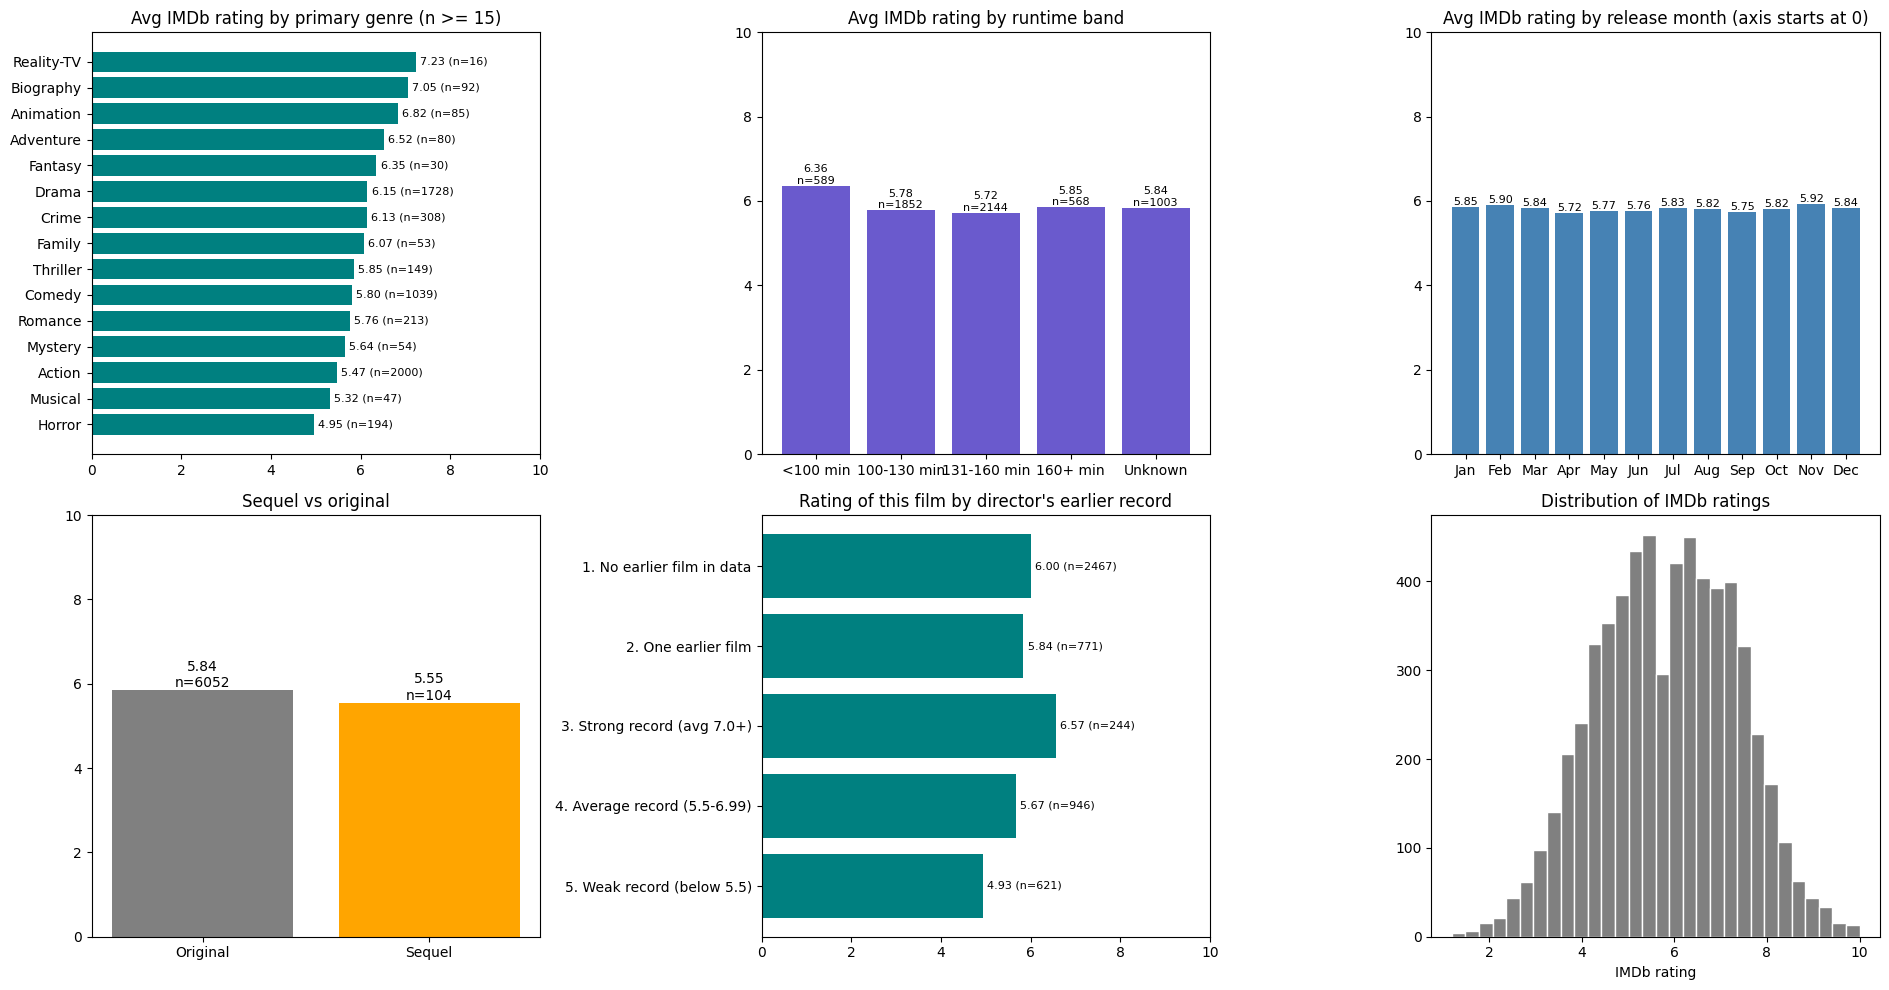

In [17]:
genre, month, runtime = genre_summary(), month_summary(), runtime_summary()
sequels, tiers = sequel_summary(), tier_summary()
ratings = q("SELECT rating FROM rated_films")["rating"]

fig, axes = plt.subplots(2, 3, figsize=(19, 10))

# genre
g = genre.sort_values("avg_rating")
bars = axes[0, 0].barh(g["primary_genre"], g["avg_rating"], color="teal")
axes[0, 0].bar_label(bars, labels=[f"{a:.2f} (n={n})" for a, n in zip(g.avg_rating, g.films)],
                     padding=3, fontsize=8)
axes[0, 0].set_xlim(0, 10)
axes[0, 0].set_title(f"Avg IMDb rating by primary genre (n >= {MIN_FILMS_PER_GROUP})")

# runtime
labels = runtime["runtime_band"].str[3:]
bars = axes[0, 1].bar(labels, runtime["avg_rating"], color="slateblue")
axes[0, 1].bar_label(bars, labels=[f"{a:.2f}\nn={n}" for a, n in zip(runtime.avg_rating, runtime.films)], fontsize=8)
axes[0, 1].set_ylim(0, 10)
axes[0, 1].set_title("Avg IMDb rating by runtime band")

# month
bars = axes[0, 2].bar(month["release_month"], month["avg_rating"], color="steelblue")
axes[0, 2].bar_label(bars, fmt="%.2f", fontsize=8)
axes[0, 2].set_ylim(0, 10)
axes[0, 2].set_title("Avg IMDb rating by release month (axis starts at 0)")

# sequel vs original
bars = axes[1, 0].bar(sequels["sequel_category"], sequels["avg_rating"], color=["grey", "orange"])
axes[1, 0].bar_label(bars, labels=[f"{a:.2f}\nn={n}" for a, n in zip(sequels.avg_rating, sequels.films)])
axes[1, 0].set_ylim(0, 10)
axes[1, 0].set_title("Sequel vs original")

# director tier
t = tiers.iloc[::-1]
bars = axes[1, 1].barh(t["director_tier"], t["avg_rating"], color="teal")
axes[1, 1].bar_label(bars, labels=[f"{a:.2f} (n={n})" for a, n in zip(t.avg_rating, t.films)], padding=3, fontsize=8)
axes[1, 1].set_xlim(0, 10)
axes[1, 1].set_title("Rating of this film by director's earlier record")

# distribution
axes[1, 2].hist(ratings, bins=30, color="grey", edgecolor="white")
axes[1, 2].set_title("Distribution of IMDb ratings")
axes[1, 2].set_xlabel("IMDb rating")

plt.tight_layout()
plt.savefig("hindi_films_charts.png", dpi=150)
plt.show()

# Three recommendations for the production house

The text below is **generated from the results above**, so each recommendation always matches the numbers in the tables.

In [18]:
genre, month, runtime = genre_summary(), month_summary(), runtime_summary()
sequels, tiers = sequel_summary(), tier_summary()

def tier_row(prefix):
    row = tiers[tiers["director_tier"].str.startswith(prefix)]
    return None if row.empty else row.iloc[0]

# ---- Recommendation 1: genre ----
top3 = genre.head(3)
low = genre.iloc[-1]
top_txt = ", ".join(f"**{r.primary_genre}** ({r.avg_rating:.2f}, n={r.films})" for r in top3.itertuples())
g_gap = genre.iloc[0].avg_rating - low.avg_rating
h1 = ("Prioritise the genres audiences rate highest" if g_gap >= 0.3
      else "Genre is only a weak signal, so choose on other grounds")
rec1 = (f"**Recommendation 1 – {h1}.** Among genres with at least "
        f"{MIN_FILMS_PER_GROUP} films, the top three are {top_txt}. The lowest is **{low.primary_genre}** "
        f"({low.avg_rating:.2f}, n={low.films}), {genre.iloc[0].avg_rating - low.avg_rating:.2f} points below the best. "
        f"Weight the development slate toward the top genres and give low-rated genres a clear reason to exist "
        f"(a strong director, a clear audience).")

# ---- Recommendation 2: director track record ----
strong, weak, none_ = tier_row("3."), tier_row("5."), tier_row("1.")
if strong is not None and weak is not None:
    gap = strong.avg_rating - weak.avg_rating
    extra = f" Films by directors with no earlier film in the data averaged {none_.avg_rating:.2f} (n={none_.films})." if none_ is not None else ""
    h2 = ("Back directors with a proven record" if gap >= 0.3
          else "Director track record is only a weak signal here")
    rec2 = (f"**Recommendation 2 – {h2}.** Films by directors whose earlier films "
            f"averaged 7.0+ scored **{strong.avg_rating:.2f}** (n={strong.films}), against **{weak.avg_rating:.2f}** "
            f"(n={weak.films}) for directors whose earlier films averaged below 5.5, a gap of {gap:.2f} points. "
            f"The earlier average and the next rating have a correlation of r = {corr_r:.2f}.{extra} "
            f"Only films from earlier years were used to build each track record.")
else:
    rec2 = "**Recommendation 2 – Director track record.** Not enough films in the strong/weak tiers to compare; see the tier table."

# ---- Recommendation 3: runtime ----
rt = runtime[~runtime["runtime_band"].str.contains("Unknown")]
best_rt, worst_rt = rt.loc[rt.avg_rating.idxmax()], rt.loc[rt.avg_rating.idxmin()]
spread = best_rt.avg_rating - worst_rt.avg_rating
strength = "a meaningful difference" if spread >= 0.5 else "only a small difference"
rec3 = (f"**Recommendation 3 – Treat runtime as a secondary lever.** The best-rated band is "
        f"**{best_rt.runtime_band[3:]}** ({best_rt.avg_rating:.2f}, n={best_rt.films}) and the lowest is "
        f"**{worst_rt.runtime_band[3:]}** ({worst_rt.avg_rating:.2f}, n={worst_rt.films}): {strength} "
        f"({spread:.2f} points). Runtime is tied to genre, so use it as a guide when planning scripts, "
        f"not as a rule on its own.")

# ---- other findings ----
m_hi, m_lo = month.loc[month.avg_rating.idxmax()], month.loc[month.avg_rating.idxmin()]
m_spread = m_hi.avg_rating - m_lo.avg_rating
m_txt = ("Release month makes little difference" if m_spread < 0.5 else "Release month shows some difference")
s_seq = sequels[sequels.sequel_category == "Sequel"]
s_org = sequels[sequels.sequel_category == "Original"]
seq_txt = ""
if len(s_seq) and len(s_org):
    seq_txt = (f" Sequels average {s_seq.iloc[0].avg_rating:.2f} (n={s_seq.iloc[0].films}) vs "
               f"{s_org.iloc[0].avg_rating:.2f} for originals (n={s_org.iloc[0].films}). "
               f"Sequel flags come from titles and were hand-checked on a sample only, so treat this as indicative.")
other = (f"**Other findings.** {m_txt}: the best month ({m_hi.release_month}, {m_hi.avg_rating:.2f}) and the worst "
         f"({m_lo.release_month}, {m_lo.avg_rating:.2f}) differ by {m_spread:.2f} points, so do not pick a release date "
         f"to chase ratings.{seq_txt}")

display(Markdown("\n\n".join([rec1, rec2, rec3, other])))

**Recommendation 1 – Prioritise the genres audiences rate highest.** Among genres with at least 15 films, the top three are **Reality-TV** (7.23, n=16), **Biography** (7.05, n=92), **Animation** (6.82, n=85). The lowest is **Horror** (4.95, n=194), 2.28 points below the best. Weight the development slate toward the top genres and give low-rated genres a clear reason to exist (a strong director, a clear audience).

**Recommendation 2 – Back directors with a proven record.** Films by directors whose earlier films averaged 7.0+ scored **6.57** (n=244), against **4.93** (n=621) for directors whose earlier films averaged below 5.5, a gap of 1.64 points. The earlier average and the next rating have a correlation of r = 0.40. Films by directors with no earlier film in the data averaged 6.00 (n=2467). Only films from earlier years were used to build each track record.

**Recommendation 3 – Treat runtime as a secondary lever.** The best-rated band is **<100 min** (6.36, n=589) and the lowest is **131-160 min** (5.72, n=2144): a meaningful difference (0.64 points). Runtime is tied to genre, so use it as a guide when planning scripts, not as a rule on its own.

**Other findings.** Release month makes little difference: the best month (Nov, 5.92) and the worst (Apr, 5.72) differ by 0.20 points, so do not pick a release date to chase ratings. Sequels average 5.55 (n=104) vs 5.84 for originals (n=6052). Sequel flags come from titles and were hand-checked on a sample only, so treat this as indicative.

### Limits of this analysis

In [19]:
n_all = len(base)
n_rated = len(rated)
n_votes = q("SELECT COUNT(*) AS n FROM rated_films_votes").iloc[0, 0]
rt_missing = rated["runtime_final"].isna().mean()
rt_known = q("SELECT COUNT(*) AS n FROM rated_films WHERE runtime_final IS NOT NULL").iloc[0, 0]

display(Markdown(f"""
1. **Ratings are not box office.** An IMDb score shows audience opinion, not profit or footfalls. A highly rated film is not always a hit.
2. **No IMDb vote counts.** The READY file has none, so films with very few votes cannot be removed directly. As a proxy, Section 8 repeats the analysis on films with at least {MIN_VOTES} **TMDB** votes ({n_votes:,} films). TMDB votes are not IMDb votes, so this is only an approximation.
3. **Runtime is partly missing.** {rt_missing:.0%} of rated films still have no runtime after filling gaps from TMDB, so runtime results use {rt_known:,} films.
4. **Sequel tagging is title-based.** It can miss sequels with unrelated titles and wrongly flag normal films (for example "Page 3"). Only a sample was checked by hand.
5. **Association, not cause.** Genre, runtime and director are linked to each other, so each finding is a pattern in past ratings, not a guaranteed effect.
6. **Data coverage.** The analysis starts from {n_all:,} films and keeps {n_rated:,} rated feature films (every drop is listed in Section 2). The director history only sees films in this dataset (1980–2023).
"""))


1. **Ratings are not box office.** An IMDb score shows audience opinion, not profit or footfalls. A highly rated film is not always a hit.
2. **No IMDb vote counts.** The READY file has none, so films with very few votes cannot be removed directly. As a proxy, Section 8 repeats the analysis on films with at least 100 **TMDB** votes (172 films). TMDB votes are not IMDb votes, so this is only an approximation.
3. **Runtime is partly missing.** 16% of rated films still have no runtime after filling gaps from TMDB, so runtime results use 5,153 films.
4. **Sequel tagging is title-based.** It can miss sequels with unrelated titles and wrongly flag normal films (for example "Page 3"). Only a sample was checked by hand.
5. **Association, not cause.** Genre, runtime and director are linked to each other, so each finding is a pattern in past ratings, not a guaranteed effect.
6. **Data coverage.** The analysis starts from 15,179 films and keeps 6,156 rated feature films (every drop is listed in Section 2). The director history only sees films in this dataset (1980–2023).


## 8. Robustness check · do the findings survive a minimum-vote filter?

The task suggests a minimum vote count. Here it is applied using TMDB votes (see Limits). If the patterns match the full sample, they are more trustworthy. Track records are still built from **all** earlier films; only the film being scored must pass the vote filter.

In [20]:
n_all_s = q("SELECT COUNT(*) AS n FROM rated_films").iloc[0, 0]
n_vote_s = q("SELECT COUNT(*) AS n FROM rated_films_votes").iloc[0, 0]
print(f"All rated feature films: {n_all_s:,}   |   with >= {MIN_VOTES} TMDB votes: {n_vote_s:,}")

def side_by_side(a, b, key):
    return a.merge(b, on=key, how="outer", suffixes=(" (all)", f" (votes>={MIN_VOTES})"))

if n_vote_s == 0:
    print("No films pass the vote filter. Check that the TMDB join matched (see Section 1).")
else:
    print("\nGENRE");   display(side_by_side(genre_summary(), genre_summary("rated_films_votes", min_n=10), "primary_genre")
                               .sort_values("avg_rating (all)", ascending=False))
    print("RUNTIME");   display(side_by_side(runtime_summary(), runtime_summary("rated_films_votes"), "runtime_band"))
    print("SEQUEL");    display(side_by_side(sequel_summary(), sequel_summary("rated_films_votes"), "sequel_category"))
    print("DIRECTOR TRACK RECORD")
    display(side_by_side(tier_summary(), tier_summary(f"WHERE vote_count >= {MIN_VOTES}"), "director_tier"))

All rated feature films: 6,156   |   with >= 100 TMDB votes: 172

GENRE


,primary_genre,films (all),avg_rating (all),films (votes>=100),avg_rating (votes>=100)
12,Reality-TV,16,7.23,NaN,NaN
3,Biography,92,7.05,NaN,NaN
2,Animation,85,6.82,NaN,NaN
1,Adventure,80,6.52,NaN,NaN
8,Fantasy,30,6.35,NaN,NaN
6,Drama,1728,6.15,32.0,7.41
5,Crime,308,6.13,13.0,7.68
7,Family,53,6.07,NaN,NaN
14,Thriller,149,5.85,NaN,NaN
4,Comedy,1039,5.80,50.0,7.27


RUNTIME


,runtime_band,films (all),avg_rating (all),films (votes>=100),avg_rating (votes>=100)
0,1. <100 min,589,6.36,4.0,5.08
1,2. 100-130 min,1852,5.78,43.0,7.25
2,3. 131-160 min,2144,5.72,83.0,7.18
3,4. 160+ min,568,5.85,42.0,7.32
4,5. Unknown,1003,5.84,NaN,NaN


SEQUEL


,sequel_category,films (all),avg_rating (all),films (votes>=100),avg_rating (votes>=100)
0,Original,6052,5.84,165,7.18
1,Sequel,104,5.55,7,7.23


DIRECTOR TRACK RECORD


,director_tier,films (all),avg_rating (all),films (votes>=100),avg_rating (votes>=100)
0,1. No earlier film in data,2467,6.00,50,7.05
1,2. One earlier film,771,5.84,35,7.45
2,3. Strong record (avg 7.0+),244,6.57,34,7.31
3,4. Average record (5.5-6.99),946,5.67,45,7.10
4,5. Weak record (below 5.5),621,4.93,8,6.76


## 9. Export

In [21]:
rated[keep].to_csv("hindi_films_rated_clean.csv", index=False)
print("Saved: hindi_films_rated_clean.csv (clean rated feature films) and hindi_films_charts.png")
conn.close()

Saved: hindi_films_rated_clean.csv (clean rated feature films) and hindi_films_charts.png


## Project checklist

| Requirement | Where |
|---|---|
| Keep rated films; say how many dropped and why | Section 2 (drop log) |
| Feature films only; minimum vote count | Section 2, Section 8 |
| Average rating by genre, month, runtime band | Section 3 |
| Sequel vs original, checked by hand | Section 4 |
| Director track record, earlier films only | Section 5 (with leak check) |
| Three recommendations backed by numbers | Section 7 |
| Limits stated | Section 7 |